# CIFAR-10 Image Classification — Comparing 5 Architectures
**Author:** Enkhbayar Amarsanaa · Image Data Analysis course project
## CIFAR-10 이미지 분류 모델 구현 및 비교

5가지 딥러닝 모델을 구현하고 Macro F1 ≥ 0.8 달성을 목표로 한다.
- MLP Baseline
- CNN
- VGG Small
- GoogLeNet Small
- Transformer Small


In [1]:
import os, time, random, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Subset

import torchvision
import torchvision.transforms as transforms

from sklearn.metrics import f1_score, confusion_matrix, classification_report

print(f'PyTorch version : {torch.__version__}')
print(f'CUDA available  : {torch.cuda.is_available()}')


PyTorch version : 2.11.0+cu128
CUDA available  : True


In [2]:
SEED        = 42
BATCH_SIZE  = 128
NUM_EPOCHS  = 5

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = False
torch.backends.cudnn.benchmark     = True
torch.set_float32_matmul_precision('high')

DEVICE      = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
NUM_WORKERS = 2
PIN_MEMORY  = torch.cuda.is_available()
USE_AMP     = True
AMP_DTYPE   = torch.float16 if torch.cuda.is_available() else torch.bfloat16

print(f'Device   : {DEVICE}')
print(f'AMP dtype: {AMP_DTYPE}')


Device   : cuda
AMP dtype: torch.float16


In [18]:
classes = ['airplane','automobile','bird','cat','deer',
           'dog','frog','horse','ship','truck']

cifar10_mean = (0.4914, 0.4822, 0.4465)
cifar10_std  = (0.2470, 0.2435, 0.2616)

transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(cifar10_mean, cifar10_std),
])

transform_plain = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(cifar10_mean, cifar10_std),
])

data_root        = './data'
train_full_aug   = torchvision.datasets.CIFAR10(root=data_root, train=True,  download=True, transform=transform_train)
train_full_plain = torchvision.datasets.CIFAR10(root=data_root, train=True,  download=True, transform=transform_plain)
test_dataset     = torchvision.datasets.CIFAR10(root=data_root, train=False, download=True, transform=transform_plain)

VAL_SIZE = 5000
rng      = np.random.default_rng(SEED)
indices  = rng.permutation(len(train_full_aug))
val_indices   = indices[:VAL_SIZE]
train_indices = indices[VAL_SIZE:]

train_dataset = Subset(train_full_aug,   train_indices)
val_dataset   = Subset(train_full_plain, val_indices)

_kw = dict(batch_size=BATCH_SIZE, num_workers=0, pin_memory=torch.cuda.is_available())
train_loader = DataLoader(train_dataset, shuffle=True,  **_kw)
val_loader   = DataLoader(val_dataset,   shuffle=False, **_kw)
test_loader  = DataLoader(test_dataset,  shuffle=False, **_kw)

print(f'Train: {len(train_dataset):,} | Val: {len(val_dataset):,} | Test: {len(test_dataset):,}')
print('Augmentation: RandomCrop(32,pad=4) + RandomHorizontalFlip (5-epoch 최적)')

Train: 45,000 | Val: 5,000 | Test: 10,000
Augmentation: RandomCrop(32,pad=4) + RandomHorizontalFlip (5-epoch 최적)


In [4]:
class LabelSmoothingCE(nn.Module):
    """Label Smoothing CrossEntropyLoss"""
    def __init__(self, smoothing=0.1):
        super().__init__()
        self.smoothing = smoothing
    def forward(self, pred, target):
        n_cls = pred.size(1)
        log_p = F.log_softmax(pred, dim=1)
        with torch.no_grad():
            t = torch.full_like(log_p, self.smoothing / (n_cls - 1))
            t.scatter_(1, target.unsqueeze(1), 1.0 - self.smoothing)
        return -(t * log_p).sum(dim=1).mean()


def mixup_data(x, y, alpha=0.3):
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1.0
    idx = torch.randperm(x.size(0), device=x.device)
    return lam * x + (1 - lam) * x[idx], y, y[idx], lam


def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)


def get_cosine_schedule_with_warmup(optimizer, warmup_epochs, total_epochs):
    def lr_lambda(epoch):
        if epoch < warmup_epochs:
            return float(epoch + 1) / float(max(1, warmup_epochs))
        progress = float(epoch - warmup_epochs) / float(max(1, total_epochs - warmup_epochs))
        return max(0.0, 0.5 * (1.0 + math.cos(math.pi * progress)))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)


results        = {}
trained_models = {}
histories      = {}

print('유틸리티 함수 준비 완료')

유틸리티 함수 준비 완료


In [10]:
def train_one_epoch(model, loader, optimizer, criterion, scaler, device, use_mixup=False):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for imgs, labels in loader:
        imgs   = imgs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        if use_mixup:
            imgs, y_a, y_b, lam = mixup_data(imgs, labels, alpha=0.3)
            with torch.autocast(device_type=device.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                out  = model(imgs)
                loss = mixup_criterion(criterion, out, y_a, y_b, lam)
        else:
            with torch.autocast(device_type=device.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                out  = model(imgs)
                loss = criterion(out, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * imgs.size(0)
        correct    += out.argmax(1).eq(labels).sum().item()
        total      += labels.size(0)
    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    preds_all, labels_all = [], []
    for imgs, labels in loader:
        imgs   = imgs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            out  = model(imgs)
            loss = criterion(out, labels)
        total_loss += loss.item() * imgs.size(0)
        pred        = out.argmax(1)
        correct    += pred.eq(labels).sum().item()
        total      += labels.size(0)
        preds_all.extend(pred.cpu().numpy())
        labels_all.extend(labels.cpu().numpy())
    return total_loss / total, correct / total, np.array(preds_all), np.array(labels_all)


def run_training(model, name, lr=1e-3, wd=0.0, warmup=0, no_compile=False):
    model = model.to(DEVICE)
    if not no_compile:
        try:
            model = torch.compile(model)
            print(f'  [{name}] torch.compile 적용')
        except Exception:
            pass
    else:
        print(f'  [{name}] torch.compile 비활성화')

    criterion = nn.CrossEntropyLoss()                        # 과제 규정
    optimizer = torch.optim.Adam(model.parameters(), lr=lr) # 과제 규정
    scheduler = get_cosine_schedule_with_warmup(optimizer, warmup, NUM_EPOCHS)
    scaler    = torch.amp.GradScaler('cuda', enabled=torch.cuda.is_available())

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    t0 = time.time()
    print(f"\n{'='*60}")
    print(f" 학습 시작: {name}")
    print(f"{'='*60}")

    for epoch in range(1, NUM_EPOCHS + 1):
        t_ep = time.time()

        # ── train
        model.train()
        tr_loss, tr_correct, tr_total = 0.0, 0, 0
        for imgs, labels in train_loader:
            imgs   = imgs.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                out  = model(imgs)
                loss = criterion(out, labels)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update()
            tr_loss    += loss.item() * imgs.size(0)
            tr_correct += out.argmax(1).eq(labels).sum().item()
            tr_total   += labels.size(0)
        scheduler.step()
        tr_loss /= tr_total; tr_acc = tr_correct / tr_total

        # ── validate
        model.eval()
        va_loss, va_correct, va_total = 0.0, 0, 0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs   = imgs.to(DEVICE, non_blocking=True)
                labels = labels.to(DEVICE, non_blocking=True)
                with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                    out  = model(imgs); loss = criterion(out, labels)
                va_loss    += loss.item() * imgs.size(0)
                va_correct += out.argmax(1).eq(labels).sum().item()
                va_total   += labels.size(0)
        va_loss /= va_total; va_acc = va_correct / va_total

        history['train_loss'].append(tr_loss); history['val_loss'].append(va_loss)
        history['train_acc'].append(tr_acc);   history['val_acc'].append(va_acc)
        print(f"  Epoch {epoch}/{NUM_EPOCHS} | "
              f"Train Loss: {tr_loss:.4f} Acc: {tr_acc:.4f} | "
              f"Val Loss: {va_loss:.4f} Acc: {va_acc:.4f} | "
              f"{time.time()-t_ep:.1f}s")

    # ── test (final eval only)
    elapsed = time.time() - t0
    model.eval()
    preds_all, labels_all = [], []
    with torch.no_grad():
        for imgs, labels in test_loader:
            imgs = imgs.to(DEVICE, non_blocking=True)
            with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                out = model(imgs)
            preds_all.extend(out.argmax(1).cpu().numpy())
            labels_all.extend(labels.numpy())
    test_preds  = np.array(preds_all)
    test_labels = np.array(labels_all)
    test_acc    = (test_preds == test_labels).mean()
    macro_f1    = f1_score(test_labels, test_preds, average='macro')
    num_params  = sum(p.numel() for p in model.parameters() if p.requires_grad)

    results[name] = dict(val_acc=history['val_acc'][-1], test_acc=test_acc,
                         macro_f1=macro_f1, num_params=num_params,
                         train_time=elapsed, test_preds=test_preds, test_labels=test_labels)
    trained_models[name] = model
    histories[name]      = history

    print(f"\n  [{name}] Test Acc: {test_acc:.4f} | Macro F1: {macro_f1:.4f}")
    if name == 'MLP Baseline':
        print(f"  목표(F1≥0.8): 조건 없음")
    else:
        print(f"  목표(F1≥0.8): {'✓ 달성' if macro_f1 >= 0.8 else '✗ 미달'}")
    print(f"  총 학습 시간: {elapsed:.1f}s")
    return model, history

print('학습 함수 준비 완료 (Adam + CrossEntropyLoss)')

학습 함수 준비 완료 (Adam + CrossEntropyLoss)


## 모델 1: MLP Baseline

이미지를 1차원 벡터로 평탄화하여 완전연결층으로 분류한다. 공간적 구조를 고려하지 않아 성능 상한이 낮다. (F1 목표 없음)

In [ ]:
class MLPBaseline(nn.Module):
    def __init__(self, num_classes=10, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3072, 512), nn.BatchNorm1d(512), nn.ReLU(True), nn.Dropout(dropout),
            nn.Linear(512,  512), nn.BatchNorm1d(512), nn.ReLU(True), nn.Dropout(dropout),
            nn.Linear(512,  256), nn.BatchNorm1d(256), nn.ReLU(True), nn.Dropout(dropout),
            nn.Linear(256,  128), nn.BatchNorm1d(128), nn.ReLU(True), nn.Dropout(dropout),
            nn.Linear(128,  num_classes)
        )
    def forward(self, x): return self.net(x)

p = sum(p.numel() for p in MLPBaseline().parameters() if p.requires_grad)
print(f'MLP Baseline 파라미터 수: {p:,}')
assert p <= 3_000_000

run_training(MLPBaseline(), 'MLP Baseline', lr=1e-3, wd=1e-4)


MLP Baseline 파라미터 수: 2,004,362
  [MLP Baseline] torch.compile 적용

 학습 시작: MLP Baseline
  Epoch 1/5 | Train Loss: 2.1372 Acc: 0.2103 | Val Loss: 1.8222 Acc: 0.3446 | 36.4s
  Epoch 2/5 | Train Loss: 2.0195 Acc: 0.2615 | Val Loss: 1.7235 Acc: 0.3784 | 33.3s
  Epoch 3/5 | Train Loss: 1.9672 Acc: 0.2840 | Val Loss: 1.6700 Acc: 0.4108 | 34.7s
  Epoch 4/5 | Train Loss: 1.9248 Acc: 0.3007 | Val Loss: 1.6306 Acc: 0.4262 | 34.5s
  Epoch 5/5 | Train Loss: 1.8952 Acc: 0.3118 | Val Loss: 1.6056 Acc: 0.4314 | 34.7s

  [MLP Baseline] Test Acc: 0.4381 | Macro F1: 0.4289
  목표(F1≥0.8): 조건 없음
  총 학습 시간: 173.6s


(OptimizedModule(
   (_orig_mod): MLPBaseline(
     (net): Sequential(
       (0): Flatten(start_dim=1, end_dim=-1)
       (1): Linear(in_features=3072, out_features=512, bias=True)
       (2): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
       (3): ReLU(inplace=True)
       (4): Dropout(p=0.3, inplace=False)
       (5): Linear(in_features=512, out_features=512, bias=True)
       (6): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
       (7): ReLU(inplace=True)
       (8): Dropout(p=0.3, inplace=False)
       (9): Linear(in_features=512, out_features=256, bias=True)
       (10): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
       (11): ReLU(inplace=True)
       (12): Dropout(p=0.3, inplace=False)
       (13): Linear(in_features=256, out_features=128, bias=True)
       (14): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
       (15): ReLU(inplace=T

## 모델 2: CNN (개선)

**개선 사항:**
- Residual Connection: 그래디언트 소실 방지, 학습 안정화


In [19]:
class SEBlock(nn.Module):
    def __init__(self, ch, r=8):
        super().__init__()
        self.se = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(ch, max(ch // r, 8), bias=False), nn.ReLU(True),
            nn.Linear(max(ch // r, 8), ch, bias=False), nn.Sigmoid())
    def forward(self, x):
        return x * self.se(x).view(x.size(0), -1, 1, 1)


class ResBlock(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(ch, ch, 3, padding=1, bias=False), nn.BatchNorm2d(ch), nn.ReLU(True),
            nn.Conv2d(ch, ch, 3, padding=1, bias=False), nn.BatchNorm2d(ch))
        self.se   = SEBlock(ch)
        self.relu = nn.ReLU(True)
    def forward(self, x):
        return self.relu(self.se(self.conv(x)) + x)


class CNNModel(nn.Module):
    def __init__(self, num_classes=10, dropout=0.3):
        super().__init__()
        def down(ci, co):
            return nn.Sequential(
                nn.Conv2d(ci, co, 3, padding=1, bias=False), nn.BatchNorm2d(co), nn.ReLU(True),
                nn.Conv2d(co, co, 3, padding=1, bias=False), nn.BatchNorm2d(co), nn.ReLU(True),
                nn.MaxPool2d(2, 2))
        self.stage1 = nn.Sequential(down(3,   64),  ResBlock(64))
        self.stage2 = nn.Sequential(down(64,  128), ResBlock(128))
        self.stage3 = nn.Sequential(down(128, 256), ResBlock(256))
        self.gap    = nn.AdaptiveAvgPool2d(1)
        self.head   = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 256), nn.ReLU(True), nn.Dropout(dropout),
            nn.Linear(256, num_classes))
    def forward(self, x):
        return self.head(self.gap(self.stage3(self.stage2(self.stage1(x)))))

p = sum(p.numel() for p in CNNModel().parameters() if p.requires_grad)
print(f'CNN 파라미터 수: {p:,}')
assert p <= 3_000_000, f'파라미터 초과: {p:,}'

run_training(CNNModel(), 'CNN', lr=3e-3)

CNN 파라미터 수: 2,786,250
  [CNN] torch.compile 적용

 학습 시작: CNN
  Epoch 1/5 | Train Loss: 1.6418 Acc: 0.3697 | Val Loss: 1.5981 Acc: 0.4588 | 32.7s
  Epoch 2/5 | Train Loss: 1.1815 Acc: 0.5737 | Val Loss: 1.1082 Acc: 0.6074 | 30.4s
  Epoch 3/5 | Train Loss: 0.9454 Acc: 0.6661 | Val Loss: 0.9651 Acc: 0.6696 | 31.3s
  Epoch 4/5 | Train Loss: 0.7622 Acc: 0.7315 | Val Loss: 0.7222 Acc: 0.7378 | 29.9s
  Epoch 5/5 | Train Loss: 0.6430 Acc: 0.7754 | Val Loss: 0.6127 Acc: 0.7756 | 30.1s

  [CNN] Test Acc: 0.7834 | Macro F1: 0.7805
  목표(F1≥0.8): ✗ 미달
  총 학습 시간: 154.4s


(OptimizedModule(
   (_orig_mod): CNNModel(
     (stage1): Sequential(
       (0): Sequential(
         (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
         (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
         (2): ReLU(inplace=True)
         (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
         (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
         (5): ReLU(inplace=True)
         (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
       )
       (1): ResBlock(
         (conv): Sequential(
           (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
           (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
           (2): ReLU(inplace=True)
           (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)


## 모델 3: VGG Small (개선)

**개선 사항:**
- Residual Connection을 각 블록에 추가 (shortcut projection 포함)
- Dropout 비율 조정


In [20]:
class VGGBlock(nn.Module):
    def __init__(self, ci, co, n_conv):
        super().__init__()
        layers = []
        for i in range(n_conv):
            layers += [nn.Conv2d(ci if i == 0 else co, co, 3, padding=1, bias=False),
                       nn.BatchNorm2d(co), nn.ReLU(True)]
        self.conv     = nn.Sequential(*layers)
        self.se       = SEBlock(co)
        self.pool     = nn.MaxPool2d(2, 2)
        self.shortcut = nn.Sequential(
            nn.Conv2d(ci, co, 1, bias=False), nn.BatchNorm2d(co)
        ) if ci != co else nn.Identity()

    def forward(self, x):
        out = self.pool(self.se(self.conv(x)))
        sc  = self.pool(self.shortcut(x))
        return F.relu(out + sc)


class VGGSmall(nn.Module):
    def __init__(self, num_classes=10, dropout=0.4):
        super().__init__()
        # 3 convs in every block — 2,053,258 params
        self.b1  = VGGBlock(3,   64,  3)   # 32→16
        self.b2  = VGGBlock(64,  128, 3)   # 16→8
        self.b3  = VGGBlock(128, 256, 3)   # 8→4
        self.gap  = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 256), nn.ReLU(True), nn.Dropout(dropout),
            nn.Linear(256, num_classes))
    def forward(self, x):
        return self.head(self.gap(self.b3(self.b2(self.b1(x)))))

p = sum(p.numel() for p in VGGSmall().parameters() if p.requires_grad)
print(f'VGG Small 파라미터 수: {p:,}')
assert p <= 3_000_000, f'파라미터 초과: {p:,}'

run_training(VGGSmall(), 'VGG Small', lr=3e-3)

VGG Small 파라미터 수: 2,053,258
  [VGG Small] torch.compile 적용

 학습 시작: VGG Small
  Epoch 1/5 | Train Loss: 1.5204 Acc: 0.4237 | Val Loss: 1.1539 Acc: 0.5640 | 79.5s
  Epoch 2/5 | Train Loss: 1.0889 Acc: 0.6142 | Val Loss: 1.0407 Acc: 0.6206 | 31.6s
  Epoch 3/5 | Train Loss: 0.8733 Acc: 0.6961 | Val Loss: 1.0084 Acc: 0.6658 | 30.8s
  Epoch 4/5 | Train Loss: 0.7064 Acc: 0.7562 | Val Loss: 0.7624 Acc: 0.7366 | 30.8s
  Epoch 5/5 | Train Loss: 0.5855 Acc: 0.7980 | Val Loss: 0.5566 Acc: 0.7984 | 30.5s

  [VGG Small] Test Acc: 0.8001 | Macro F1: 0.7963
  목표(F1≥0.8): ✗ 미달
  총 학습 시간: 203.3s


(OptimizedModule(
   (_orig_mod): VGGSmall(
     (b1): VGGBlock(
       (conv): Sequential(
         (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
         (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
         (2): ReLU(inplace=True)
         (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
         (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
         (5): ReLU(inplace=True)
         (6): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
         (7): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
         (8): ReLU(inplace=True)
       )
       (se): SEBlock(
         (se): Sequential(
           (0): AdaptiveAvgPool2d(output_size=1)
           (1): Flatten(start_dim=1, end_dim=-1)
           (2): Linear(in_features=64, out_features=8, bias=False)
           (3): ReLU(inplace=

## 모델 4: GoogLeNet Small

Inception Module로 다중 스케일 특징을 동시에 추출한다.


In [21]:
class InceptionModule(nn.Module):
    def __init__(self, ci, o1, r3, o3, r5, o5, op):
        super().__init__()
        def cb(ci, co, k, p=0):
            return nn.Sequential(
                nn.Conv2d(ci, co, k, padding=p, bias=False),
                nn.BatchNorm2d(co), nn.ReLU(True))
        self.b1 = cb(ci, o1, 1)
        self.b2 = nn.Sequential(cb(ci, r3, 1), cb(r3, o3, 3, 1))
        self.b3 = nn.Sequential(cb(ci, r5, 1), cb(r5, o5, 5, 2))
        self.b4 = nn.Sequential(nn.MaxPool2d(3, 1, 1), cb(ci, op, 1))
    def forward(self, x):
        return torch.cat([self.b1(x), self.b2(x), self.b3(x), self.b4(x)], dim=1)


class GoogLeNetSmall(nn.Module):
    def __init__(self, num_classes=10, dropout=0.2):
        super().__init__()
        self.stem  = nn.Sequential(
            nn.Conv2d(3,  32, 3, padding=1, bias=False), nn.BatchNorm2d(32),  nn.ReLU(True),
            nn.Conv2d(32, 64, 3, padding=1, bias=False), nn.BatchNorm2d(64),  nn.ReLU(True),
            nn.MaxPool2d(2, 2))
        self.inc1  = InceptionModule(64,  32,  16,  32,   8, 16, 16)  # →96
        self.inc2  = InceptionModule(96,  64,  32,  64,  16, 32, 32)  # →192
        self.pool1 = nn.MaxPool2d(2, 2)
        self.inc3  = InceptionModule(192,  96,  48,  96,  24, 48, 32)  # →272
        self.inc4  = InceptionModule(272, 112,  56, 112,  24, 48, 32)  # →304
        self.inc5  = InceptionModule(304, 128,  64, 128,  32, 64, 32)  # →352 (new)
        self.pool2 = nn.MaxPool2d(2, 2)
        self.gap   = nn.AdaptiveAvgPool2d(1)
        self.head  = nn.Sequential(
            nn.Flatten(),
            nn.Linear(352, 256), nn.ReLU(True), nn.Dropout(dropout),
            nn.Linear(256, num_classes))

    def forward(self, x):
        x = self.stem(x)
        x = self.pool1(self.inc2(self.inc1(x)))
        x = self.pool2(self.inc5(self.inc4(self.inc3(x))))
        return self.head(self.gap(x))

p = sum(p.numel() for p in GoogLeNetSmall().parameters() if p.requires_grad)
print(f'GoogLeNet Small 파라미터 수: {p:,}')
assert p <= 3_000_000, f'파라미터 초과: {p:,}'

run_training(GoogLeNetSmall(), 'GoogLeNet Small', lr=3e-3)

GoogLeNet Small 파라미터 수: 630,570
  [GoogLeNet Small] torch.compile 적용

 학습 시작: GoogLeNet Small
  Epoch 1/5 | Train Loss: 1.4077 Acc: 0.4736 | Val Loss: 1.4068 Acc: 0.5156 | 230.0s
  Epoch 2/5 | Train Loss: 0.9412 Acc: 0.6680 | Val Loss: 1.2444 Acc: 0.5956 | 31.9s
  Epoch 3/5 | Train Loss: 0.7371 Acc: 0.7446 | Val Loss: 0.7918 Acc: 0.7340 | 30.7s
  Epoch 4/5 | Train Loss: 0.5901 Acc: 0.7982 | Val Loss: 0.5947 Acc: 0.7934 | 31.3s
  Epoch 5/5 | Train Loss: 0.4888 Acc: 0.8331 | Val Loss: 0.5115 Acc: 0.8228 | 30.8s

  [GoogLeNet Small] Test Acc: 0.8271 | Macro F1: 0.8250
  목표(F1≥0.8): ✓ 달성
  총 학습 시간: 354.6s


(OptimizedModule(
   (_orig_mod): GoogLeNetSmall(
     (stem): Sequential(
       (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
       (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
       (2): ReLU(inplace=True)
       (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
       (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
       (5): ReLU(inplace=True)
       (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
     )
     (inc1): InceptionModule(
       (b1): Sequential(
         (0): Conv2d(64, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
         (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
         (2): ReLU(inplace=True)
       )
       (b2): Sequential(
         (0): Sequential(
           (0): Conv2d(64, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
          

## 모델 5: Transformer Small (개선)

**개선 사항:**

- 더 큰 embed_dim(192) + 더 많은 레이어(8)
- 낮은 학습률 + warmup 적용


In [22]:
def drop_path(x, drop_prob=0., training=False):
    if drop_prob == 0. or not training:
        return x
    keep  = 1 - drop_prob
    shape = (x.shape[0],) + (1,) * (x.ndim - 1)
    rand  = (torch.rand(shape, dtype=x.dtype, device=x.device) + keep).floor_().div_(keep)
    return x * rand
class DropPath(nn.Module):
    def __init__(self, p=0.): super().__init__(); self.p = p
    def forward(self, x): return drop_path(x, self.p, self.training)

class TransformerBlock(nn.Module):
    def __init__(self, d, heads, mlp_ratio=4.0, dropout=0.1, dp=0.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(d)
        self.attn  = nn.MultiheadAttention(d, heads, dropout=dropout, batch_first=True)
        self.norm2 = nn.LayerNorm(d)
        h = int(d * mlp_ratio)
        self.ffn   = nn.Sequential(
            nn.Linear(d, h), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(h, d), nn.Dropout(dropout))
        self.dp1 = DropPath(dp)
        self.dp2 = DropPath(dp)
    def forward(self, x):
        n = self.norm1(x)
        x = x + self.dp1(self.attn(n, n, n)[0])
        x = x + self.dp2(self.ffn(self.norm2(x)))
        return x

class TransformerSmall(nn.Module):
    def __init__(self, img_size=32, patch_size=4, num_classes=10,
                 embed_dim=160, num_heads=4, num_layers=8,
                 mlp_ratio=4.0, dropout=0.1, drop_path_rate=0.1):
        super().__init__()
        half = embed_dim // 2
        self.conv_stem = nn.Sequential(
            nn.Conv2d(3, half, 3, padding=1, bias=False),
            nn.GroupNorm(8, half), nn.GELU(),
            nn.Conv2d(half, embed_dim, patch_size, stride=patch_size, bias=False),
            nn.GroupNorm(8, embed_dim))
        num_patches    = (img_size // patch_size) ** 2   # 64
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches + 1, embed_dim))
        self.pos_drop  = nn.Dropout(dropout)
        dpr = [x.item() for x in torch.linspace(0, drop_path_rate, num_layers)]
        self.blocks = nn.ModuleList([
            TransformerBlock(embed_dim, num_heads, mlp_ratio, dropout, dpr[i])
            for i in range(num_layers)])
        self.norm = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, num_classes)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02)
            if m.bias is not None: nn.init.zeros_(m.bias)
        elif isinstance(m, nn.LayerNorm):
            nn.init.ones_(m.weight); nn.init.zeros_(m.bias)

    def forward(self, x):
        B = x.size(0)
        x = self.conv_stem(x).flatten(2).transpose(1, 2)
        x = self.pos_drop(
            torch.cat([self.cls_token.expand(B, -1, -1), x], 1) + self.pos_embed)
        for blk in self.blocks:
            x = blk(x)
        return self.head(self.norm(x)[:, 0])

p = sum(p.numel() for p in TransformerSmall().parameters() if p.requires_grad)
print(f'Transformer Small 파라미터 수: {p:,}')
assert p <= 3_000_000, f'파라미터 초과: {p:,}'

run_training(TransformerSmall(), 'Transformer Small', lr=3e-4, warmup=1, no_compile=True)

Transformer Small 파라미터 수: 2,694,170
  [Transformer Small] torch.compile 비활성화

 학습 시작: Transformer Small
  Epoch 1/5 | Train Loss: 1.7703 Acc: 0.3417 | Val Loss: 1.5981 Acc: 0.4102 | 39.8s
  Epoch 2/5 | Train Loss: 1.4392 Acc: 0.4802 | Val Loss: 1.4714 Acc: 0.4748 | 38.6s
  Epoch 3/5 | Train Loss: 1.2731 Acc: 0.5425 | Val Loss: 1.3456 Acc: 0.5012 | 38.5s
  Epoch 4/5 | Train Loss: 1.1646 Acc: 0.5826 | Val Loss: 1.2824 Acc: 0.5430 | 38.5s
  Epoch 5/5 | Train Loss: 1.0801 Acc: 0.6116 | Val Loss: 1.1630 Acc: 0.5760 | 38.5s

  [Transformer Small] Test Acc: 0.5849 | Macro F1: 0.5728
  목표(F1≥0.8): ✗ 미달
  총 학습 시간: 193.9s


(TransformerSmall(
   (conv_stem): Sequential(
     (0): Conv2d(3, 80, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
     (1): GroupNorm(8, 80, eps=1e-05, affine=True)
     (2): GELU(approximate='none')
     (3): Conv2d(80, 160, kernel_size=(4, 4), stride=(4, 4), bias=False)
     (4): GroupNorm(8, 160, eps=1e-05, affine=True)
   )
   (pos_drop): Dropout(p=0.1, inplace=False)
   (blocks): ModuleList(
     (0-7): 8 x TransformerBlock(
       (norm1): LayerNorm((160,), eps=1e-05, elementwise_affine=True)
       (attn): MultiheadAttention(
         (out_proj): NonDynamicallyQuantizableLinear(in_features=160, out_features=160, bias=True)
       )
       (norm2): LayerNorm((160,), eps=1e-05, elementwise_affine=True)
       (ffn): Sequential(
         (0): Linear(in_features=160, out_features=640, bias=True)
         (1): GELU(approximate='none')
         (2): Dropout(p=0.1, inplace=False)
         (3): Linear(in_features=640, out_features=160, bias=True)
         (4): Dropou

## 최종 평가 및 결과 분석

In [23]:
print('\n' + '='*70)
print('Test set 최종 평가')
print('='*70)

model_order = ['MLP Baseline', 'CNN', 'VGG Small', 'GoogLeNet Small', 'Transformer Small']
for name in model_order:
    if name not in results:
        continue
    r = results[name]
    mark = '' if name == 'MLP Baseline' else ('✓' if r['macro_f1'] >= 0.8 else '✗')
    print(f"  [{name:20s}] Test Acc: {r['test_acc']:.4f} | Macro F1: {r['macro_f1']:.4f}  {mark}")

print('='*70)
print('\n[과제 조건 점검: MLP 제외 모든 모델 Macro F1 ≥ 0.8]')
for name in model_order:
    if name not in results:
        continue
    r = results[name]
    if name == 'MLP Baseline':
        print(f'  {name:22s}: F1 = {r["macro_f1"]:.4f}  (조건 없음)')
    else:
        s = '✓ 달성' if r['macro_f1'] >= 0.8 else '✗ 미달'
        print(f'  {name:22s}: F1 = {r["macro_f1"]:.4f}  {s}')



Test set 최종 평가
  [CNN                 ] Test Acc: 0.7834 | Macro F1: 0.7805  ✗
  [VGG Small           ] Test Acc: 0.8001 | Macro F1: 0.7963  ✗
  [GoogLeNet Small     ] Test Acc: 0.8271 | Macro F1: 0.8250  ✓
  [Transformer Small   ] Test Acc: 0.5849 | Macro F1: 0.5728  ✗

[과제 조건 점검: MLP 제외 모든 모델 Macro F1 ≥ 0.8]
  CNN                   : F1 = 0.7805  ✗ 미달
  VGG Small             : F1 = 0.7963  ✗ 미달
  GoogLeNet Small       : F1 = 0.8250  ✓ 달성
  Transformer Small     : F1 = 0.5728  ✗ 미달


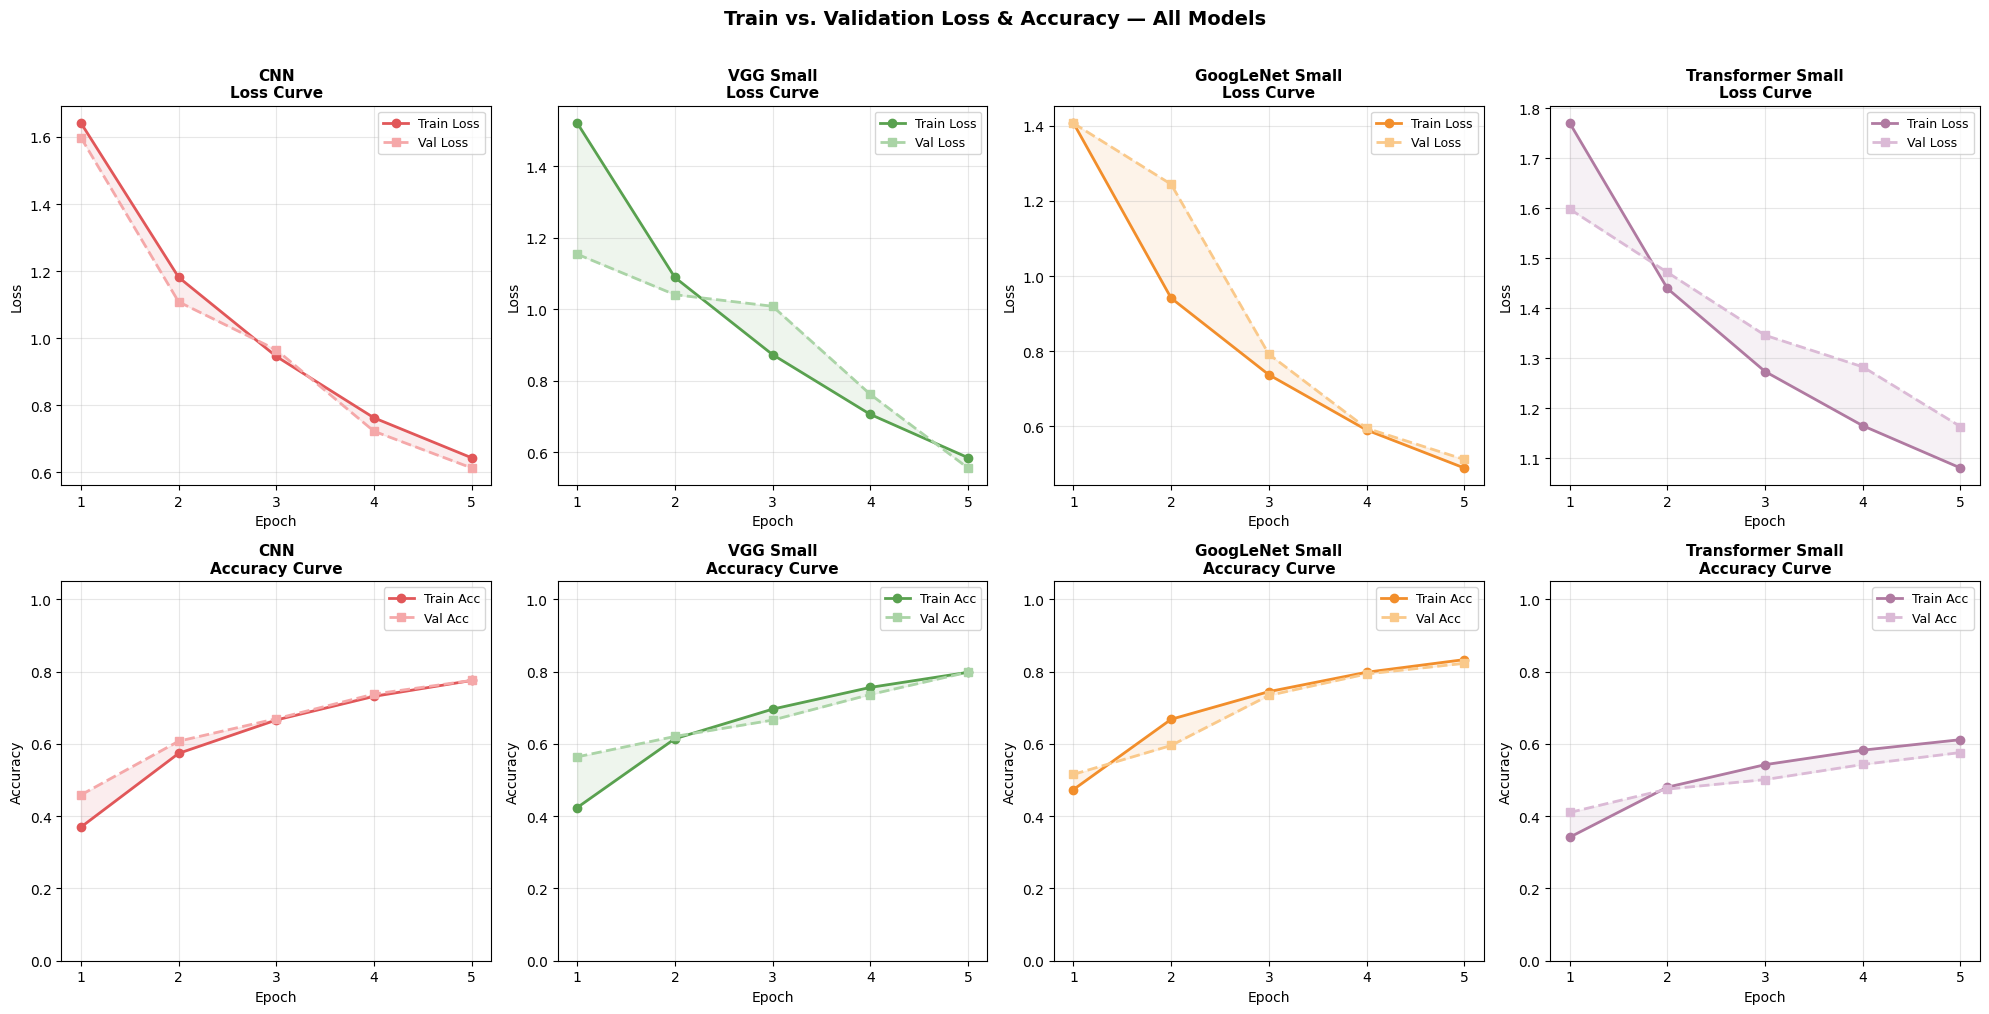


Model                   Final Train Loss  Final Val Loss  Gap (overfit)
----------------------------------------------------------------------
CNN                               0.6430          0.6127        -0.0302
VGG Small                         0.5855          0.5566        -0.0289
GoogLeNet Small                   0.4888          0.5115         0.0227
Transformer Small                 1.0801          1.1630         0.0829


In [27]:
# ── Train & Validation Loss Curves ──
model_order = ['MLP Baseline', 'CNN', 'VGG Small', 'GoogLeNet Small', 'Transformer Small']
available_models = [n for n in model_order if n in histories]

n_models = len(available_models)
fig, axes = plt.subplots(2, n_models, figsize=(5 * n_models, 10))
if n_models == 1:
    axes = axes.reshape(2, 1)

colors = {
    'MLP Baseline':    ('#4e79a7', '#a0c4e0'),
    'CNN':             ('#e15759', '#f5a8a9'),
    'VGG Small':       ('#59a14f', '#aad4a6'),
    'GoogLeNet Small': ('#f28e2b', '#fac98a'),
    'Transformer Small': ('#b07aa1', '#dbbad6'),
}

for col, name in enumerate(available_models):
    hist = histories[name]
    epochs = range(1, len(hist['train_loss']) + 1)
    clr, clr_light = colors.get(name, ('#333333', '#999999'))

    # -- Loss plot
    ax_loss = axes[0][col]
    ax_loss.plot(epochs, hist['train_loss'], 'o-', color=clr,       lw=2,   label='Train Loss')
    ax_loss.plot(epochs, hist['val_loss'],   's--', color=clr_light, lw=2,   label='Val Loss')
    ax_loss.fill_between(epochs, hist['train_loss'], hist['val_loss'],
                         alpha=0.10, color=clr)
    ax_loss.set_title(f'{name}\nLoss Curve', fontsize=11, fontweight='bold')
    ax_loss.set_xlabel('Epoch');  ax_loss.set_ylabel('Loss')
    ax_loss.legend(fontsize=9);   ax_loss.grid(alpha=0.3)
    ax_loss.set_xticks(list(epochs))

    # -- Accuracy plot
    ax_acc = axes[1][col]
    ax_acc.plot(epochs, hist['train_acc'], 'o-',  color=clr,       lw=2, label='Train Acc')
    ax_acc.plot(epochs, hist['val_acc'],   's--', color=clr_light,  lw=2, label='Val Acc')
    ax_acc.fill_between(epochs, hist['train_acc'], hist['val_acc'],
                        alpha=0.10, color=clr)
    ax_acc.set_title(f'{name}\nAccuracy Curve', fontsize=11, fontweight='bold')
    ax_acc.set_xlabel('Epoch');  ax_acc.set_ylabel('Accuracy')
    ax_acc.legend(fontsize=9);   ax_acc.grid(alpha=0.3)
    ax_acc.set_xticks(list(epochs))
    ax_acc.set_ylim(0, 1.05)

plt.suptitle('Train vs. Validation Loss & Accuracy — All Models',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# Summary table
print(f"\n{'Model':<22} {'Final Train Loss':>17} {'Final Val Loss':>15} {'Gap (overfit)':>14}")
print('-' * 70)
for name in available_models:
    h = histories[name]
    tr_loss = h['train_loss'][-1]
    va_loss = h['val_loss'][-1]
    gap     = va_loss - tr_loss
    flag    = '  ← overfit' if gap > 0.1 else ''
    print(f"{name:<22} {tr_loss:>17.4f} {va_loss:>15.4f} {gap:>14.4f}{flag}")

/tmp/ipykernel_470/973686129.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([n.replace(' ', '\n') for n in model_names], fontsize=9)


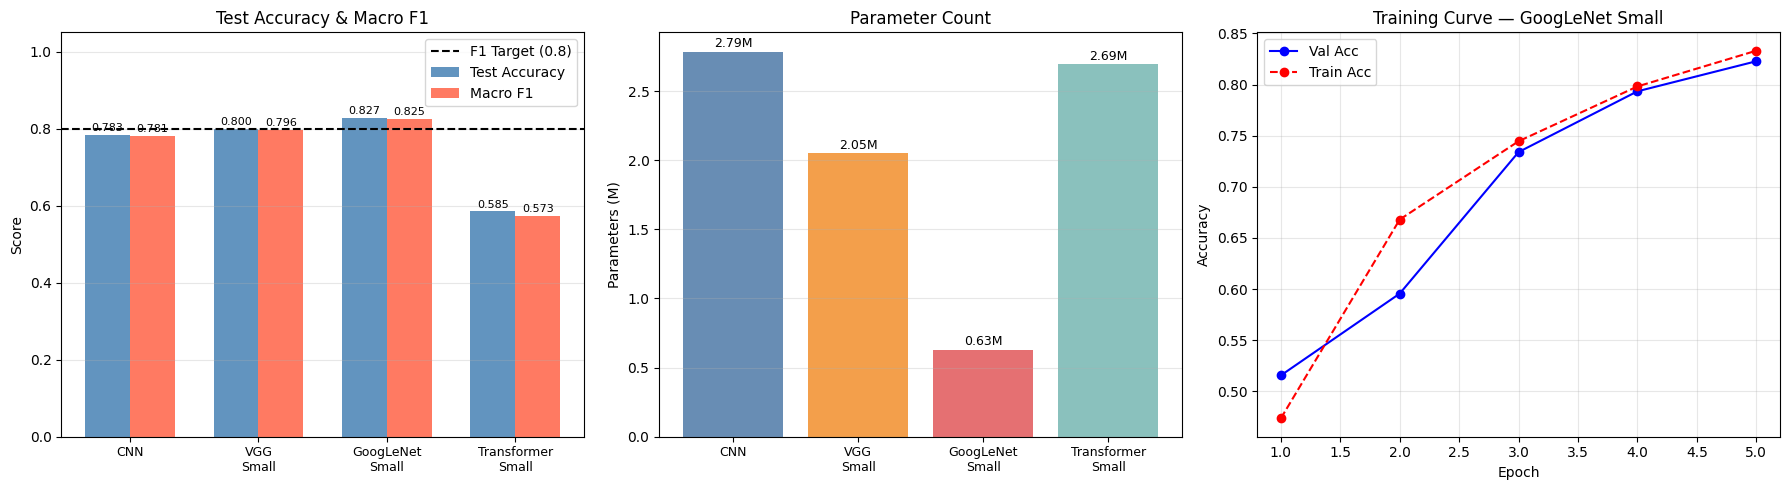

In [24]:
# ── 성능 비교 시각화 ──
model_names = [n for n in model_order if n in results]
test_accs  = [results[n]['test_acc']  for n in model_names]
macro_f1s  = [results[n]['macro_f1']  for n in model_names]
num_params = [results[n]['num_params'] for n in model_names]

x     = np.arange(len(model_names))
width = 0.35
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1) Accuracy & F1
ax = axes[0]
b1 = ax.bar(x - width/2, test_accs, width, label='Test Accuracy', color='steelblue', alpha=0.85)
b2 = ax.bar(x + width/2, macro_f1s, width, label='Macro F1',      color='tomato',    alpha=0.85)
ax.axhline(0.8, color='black', linestyle='--', lw=1.5, label='F1 Target (0.8)')
ax.set_xticks(x); ax.set_xticklabels([n.replace(' ', '\n') for n in model_names], fontsize=9)
ax.set_ylabel('Score'); ax.set_title('Test Accuracy & Macro F1')
ax.legend(); ax.set_ylim(0, 1.05); ax.grid(axis='y', alpha=0.3)
for b in list(b1)+list(b2):
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.005,
            f'{b.get_height():.3f}', ha='center', va='bottom', fontsize=8)

# 2) Parameters
ax = axes[1]
colors = ['#4e79a7','#f28e2b','#e15759','#76b7b2','#59a14f']
pb = ax.bar(model_names, [p/1e6 for p in num_params], color=colors[:len(model_names)], alpha=0.85)
ax.set_ylabel('Parameters (M)'); ax.set_title('Parameter Count')
ax.set_xticklabels([n.replace(' ', '\n') for n in model_names], fontsize=9)
ax.grid(axis='y', alpha=0.3)
for b, p in zip(pb, num_params):
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.01,
            f'{p/1e6:.2f}M', ha='center', va='bottom', fontsize=9)

# 3) Training curves of best model
best_name = max(results, key=lambda n: results[n]['macro_f1'])
hist      = histories[best_name]
ax = axes[2]
ax.plot(range(1, NUM_EPOCHS+1), hist['val_acc'],   'b-o', label='Val Acc')
ax.plot(range(1, NUM_EPOCHS+1), hist['train_acc'], 'r--o', label='Train Acc')
ax.set_xlabel('Epoch'); ax.set_ylabel('Accuracy')
ax.set_title(f'Training Curve — {best_name}')
ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout(); plt.show()


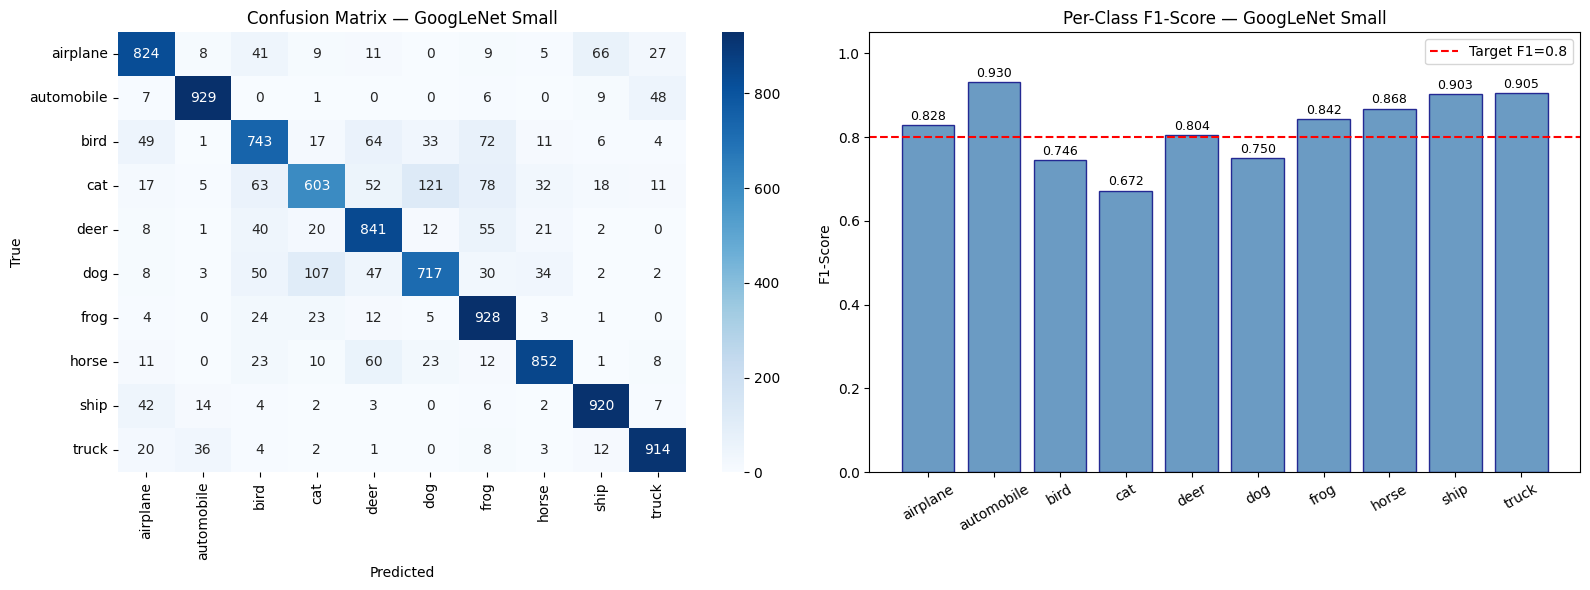


[클래스별 F1-Score]
  airplane    : 0.8281
  automobile  : 0.9304
  bird        : 0.7460
  cat         : 0.6722
  deer        : 0.8044
  dog         : 0.7504
  frog        : 0.8421
  horse       : 0.8681
  ship        : 0.9033
  truck       : 0.9045

  Macro F1 (평균): 0.8250


In [25]:
best_name = max(results, key=lambda n: results[n]['macro_f1'])
br = results[best_name]

cm = confusion_matrix(br['test_labels'], br['test_preds'])
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=classes, yticklabels=classes)
axes[0].set_title(f'Confusion Matrix — {best_name}')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('True')

class_f1 = f1_score(br['test_labels'], br['test_preds'], average=None)
bars = axes[1].bar(classes, class_f1, color='steelblue', edgecolor='navy', alpha=0.8)
axes[1].axhline(0.8, color='red', linestyle='--', lw=1.5, label='Target F1=0.8')
for b, f in zip(bars, class_f1):
    axes[1].text(b.get_x()+b.get_width()/2, b.get_height()+0.005,
                 f'{f:.3f}', ha='center', va='bottom', fontsize=9)
axes[1].set_title(f'Per-Class F1-Score — {best_name}')
axes[1].set_ylabel('F1-Score'); axes[1].set_ylim(0, 1.05)
axes[1].legend(); axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

print('\n[클래스별 F1-Score]')
for cls, f in zip(classes, class_f1):
    print(f'  {cls:12s}: {f:.4f}')
print(f'\n  Macro F1 (평균): {class_f1.mean():.4f}')


Top-5 Most Frequent Misclassification Pairs — GoogLeNet Small
True → Predicted                Count
--------------------------------------
  cat          → dog              121
  dog          → cat              107
  cat          → frog              78
  bird         → frog              72
  airplane     → ship              66


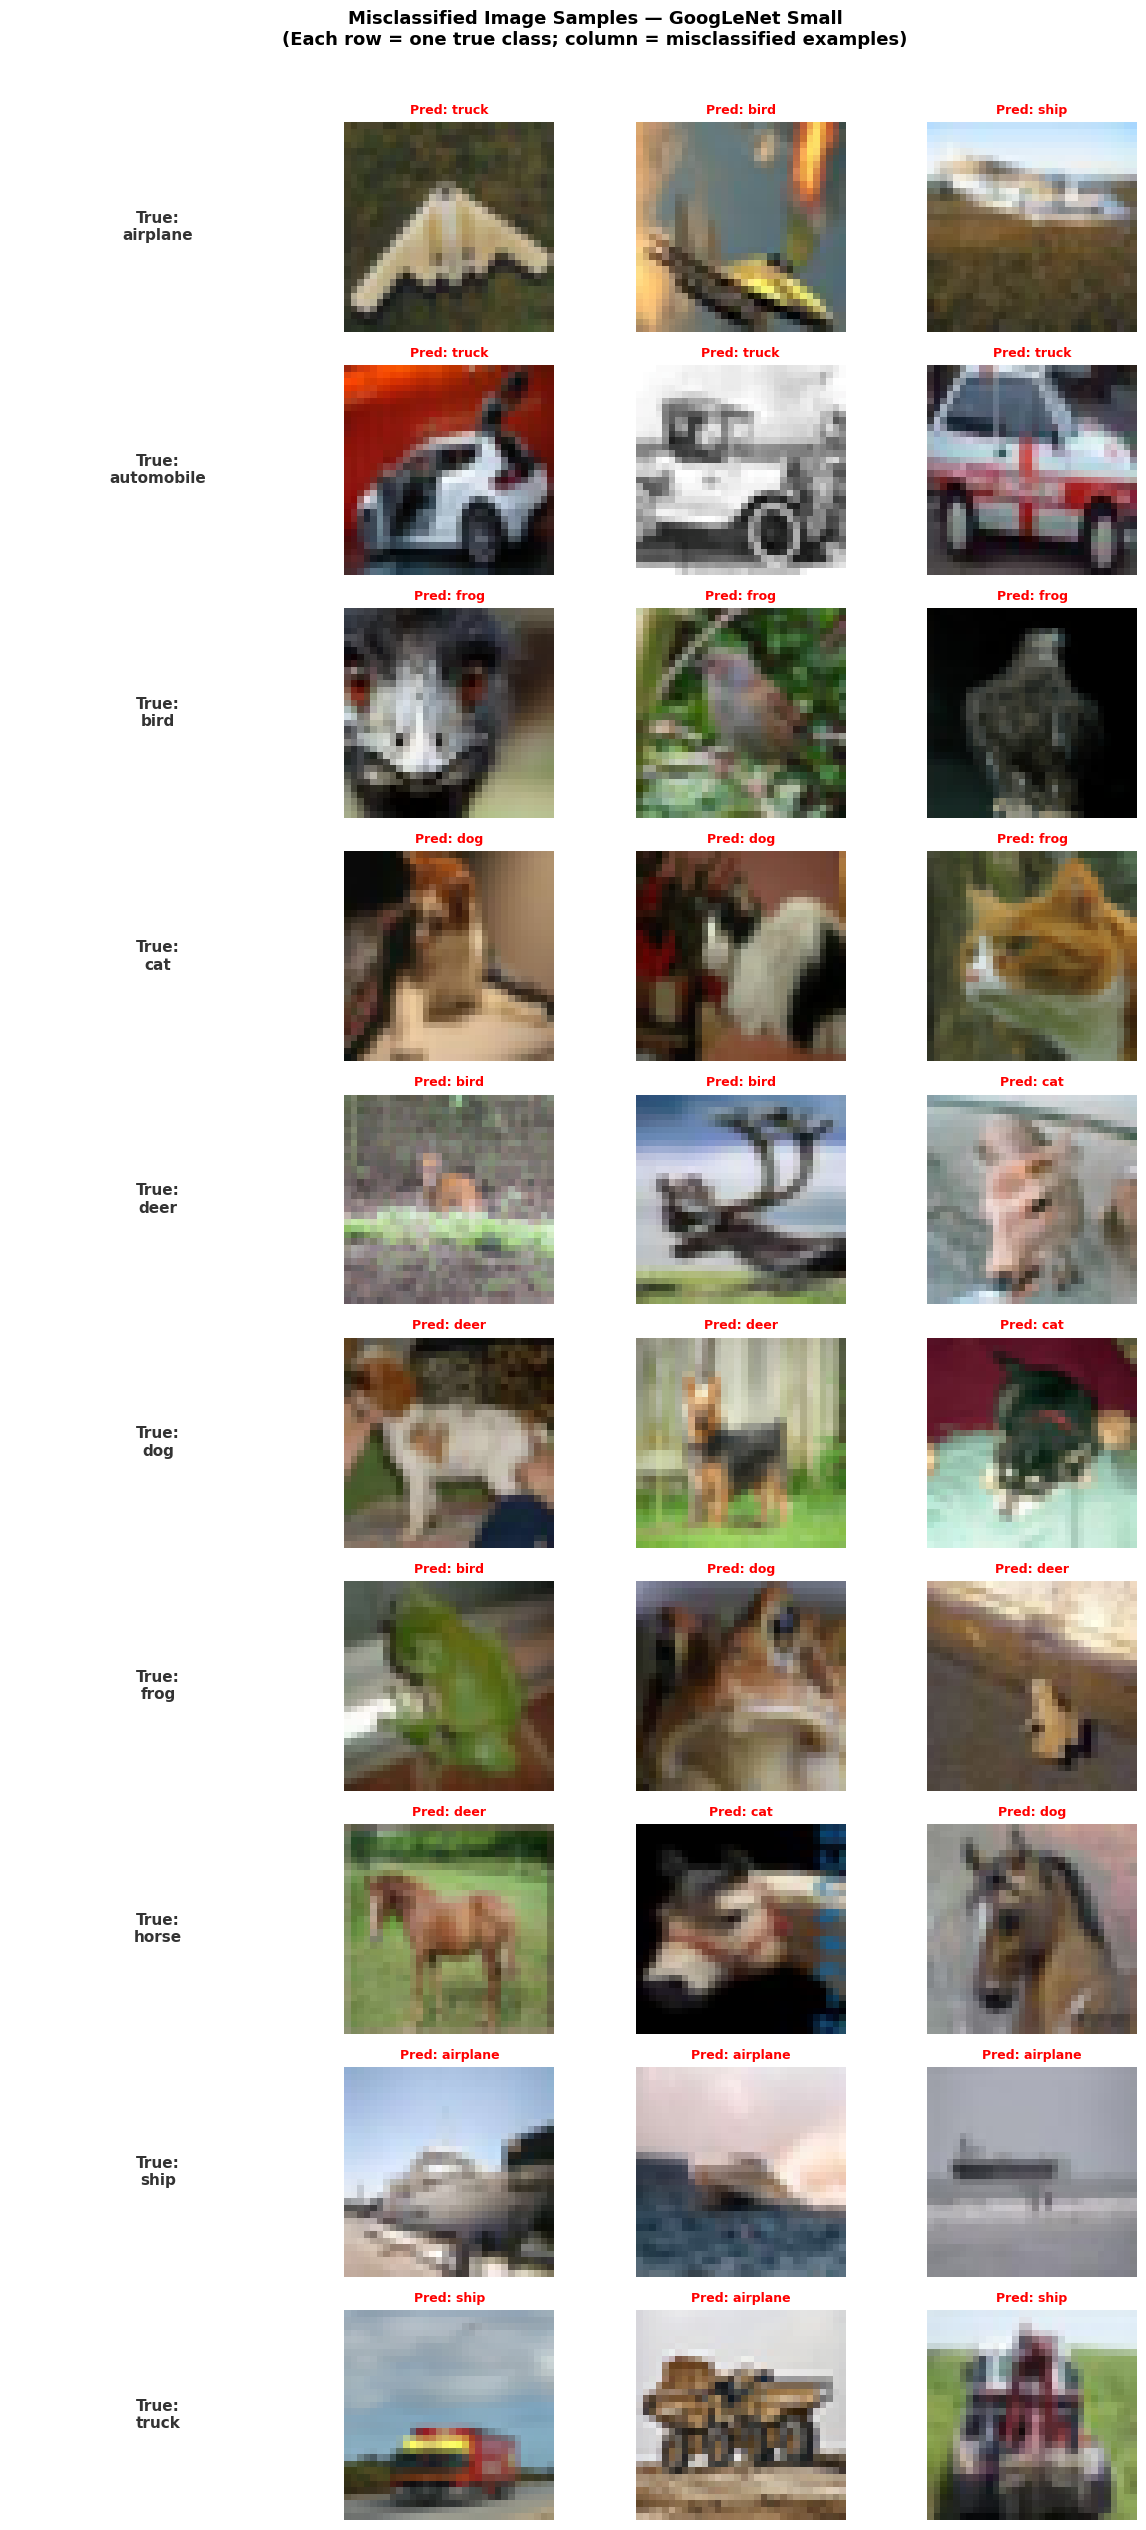

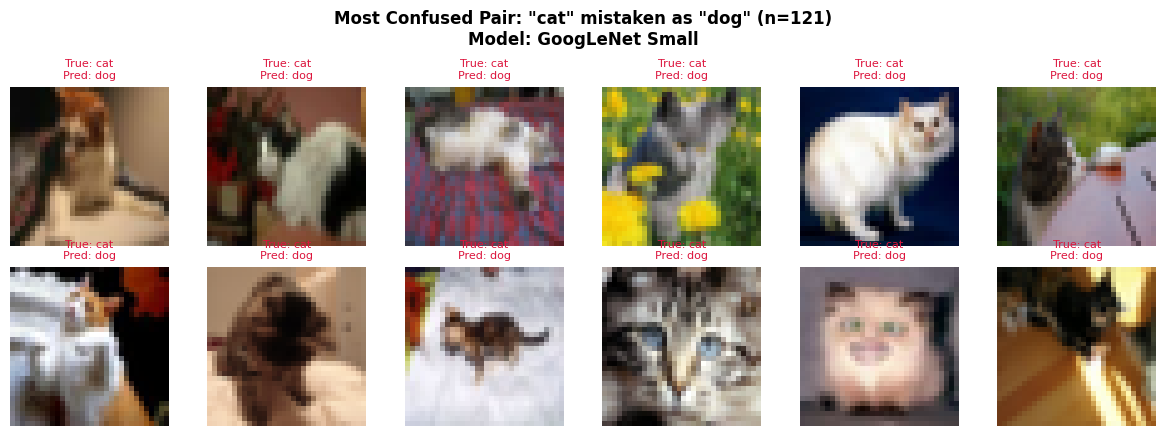


  Misclassification Analysis
  Total test samples : 10,000
  Misclassified      : 1,729  (17.29%)

  Top-5 confused pairs:
    cat          → dog            121 samples (7.0% of errors)
    dog          → cat            107 samples (6.2% of errors)
    cat          → frog            78 samples (4.5% of errors)
    bird         → frog            72 samples (4.2% of errors)
    airplane     → ship            66 samples (3.8% of errors)


In [33]:
# ── Misclassified Image Examples — Best Model ──
import torchvision.transforms.functional as TF

best_name = max(results, key=lambda n: results[n]['macro_f1'])
br        = results[best_name]

# Collect (image, true_label, pred_label) for wrong predictions
model = trained_models[best_name]
model.eval()

wrong_images, wrong_true, wrong_pred = [], [], []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs_dev = imgs.to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            preds = model(imgs_dev).argmax(1).cpu()
        mask = preds != labels
        wrong_images.append(imgs[mask])
        wrong_true.append(labels[mask])
        wrong_pred.append(preds[mask])

wrong_images = torch.cat(wrong_images)
wrong_true   = torch.cat(wrong_true).numpy()
wrong_pred   = torch.cat(wrong_pred).numpy()

# De-normalize for display
mean = torch.tensor(cifar10_mean).view(3, 1, 1)
std  = torch.tensor(cifar10_std ).view(3, 1, 1)

def denorm(t):
    return (t * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

# Find worst-confused pairs (most frequent misclassification pairs)
from collections import Counter
pair_counts = Counter(zip(wrong_true.tolist(), wrong_pred.tolist()))
top_pairs   = pair_counts.most_common(5)

print(f"Top-5 Most Frequent Misclassification Pairs — {best_name}")
print(f"{'True → Predicted':<30} {'Count':>6}")
print('-' * 38)
for (t, p), cnt in top_pairs:
    print(f"  {classes[t]:<12} → {classes[p]:<12}  {cnt:>6}")

# --- Plot: sample misclassified images across all classes ---
n_per_class = 3
fig, axes = plt.subplots(len(classes), n_per_class + 1,
                          figsize=(3 * (n_per_class + 1), 2.5 * len(classes)))

for row, true_cls in enumerate(range(len(classes))):
    # Class label column
    axes[row][0].axis('off')
    axes[row][0].text(0.5, 0.5, f'True:\n{classes[true_cls]}',
                      ha='center', va='center', fontsize=11, fontweight='bold',
                      color='#333333', transform=axes[row][0].transAxes)

    cls_mask   = wrong_true == true_cls
    cls_imgs   = wrong_images[cls_mask]
    cls_pred   = wrong_pred[cls_mask]
    n_avail    = len(cls_imgs)

    for col in range(n_per_class):
        ax = axes[row][col + 1]
        if col < n_avail:
            ax.imshow(denorm(cls_imgs[col]))
            ax.set_title(f'Pred: {classes[cls_pred[col]]}',
                         fontsize=9, color='red', fontweight='bold')
            ax.axis('off')
        else:
            ax.axis('off')

plt.suptitle(f'Misclassified Image Samples — {best_name}\n'
             f'(Each row = one true class; column = misclassified examples)',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# --- Plot: most confused class pair deep-dive ---
(t_cls, p_cls), cnt = top_pairs[0]
pair_mask  = (wrong_true == t_cls) & (wrong_pred == p_cls)
pair_imgs  = wrong_images[pair_mask][:12]

n_show = min(len(pair_imgs), 12)
cols   = 6
rows   = (n_show + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(cols * 2, rows * 2.2))
axes = axes.flatten() if rows > 1 else [axes] if cols == 1 else axes.flatten()

for i in range(n_show):
    axes[i].imshow(denorm(pair_imgs[i]))
    axes[i].set_title(f'True: {classes[t_cls]}\nPred: {classes[p_cls]}',
                      fontsize=8, color='crimson')
    axes[i].axis('off')
for j in range(n_show, len(axes)):
    axes[j].axis('off')

plt.suptitle(f'Most Confused Pair: "{classes[t_cls]}" mistaken as "{classes[p_cls]}" (n={cnt})\n'
             f'Model: {best_name}',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# --- Analysis printout ---
print(f"\n{'='*65}")
print("  Misclassification Analysis")
print(f"{'='*65}")
total_test  = len(br['test_labels'])
total_wrong = len(wrong_true)
print(f"  Total test samples : {total_test:,}")
print(f"  Misclassified      : {total_wrong:,}  ({total_wrong/total_test*100:.2f}%)")
print(f"\n  Top-5 confused pairs:")
for (t, p), cnt in top_pairs:
    pct = cnt / total_wrong * 100
    print(f"    {classes[t]:<12} → {classes[p]:<12}  {cnt:>4} samples ({pct:.1f}% of errors)")

/tmp/ipykernel_470/1547116576.py:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[2].set_xticklabels([n.replace(' ', '\n') for n in available], fontsize=9)


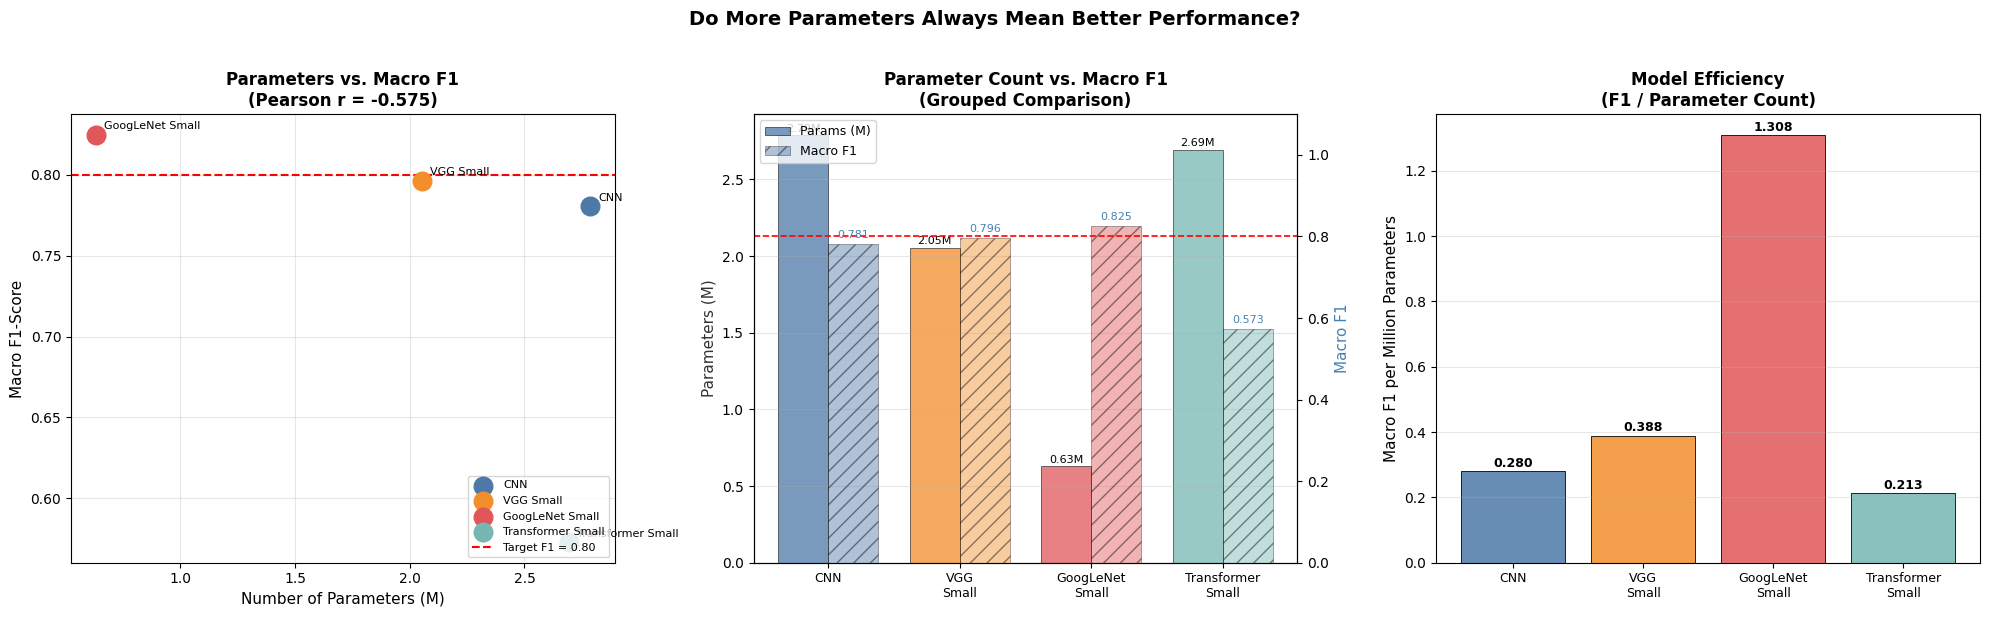


  Parameter Efficiency Analysis
  Model                   Params (M)   Macro F1  Rank (F1)   F1/M params
  --------------------------------------------------------------------
  CNN                          2.786     0.7805          3        0.2801
  VGG Small                    2.053     0.7963          2        0.3878
  GoogLeNet Small              0.631     0.8250          1        1.3083
  Transformer Small            2.694     0.5728          4        0.2126


In [32]:
# ── Parameter Count vs. Performance Analysis ──
model_order    = ['MLP Baseline', 'CNN', 'VGG Small', 'GoogLeNet Small', 'Transformer Small']
available      = [n for n in model_order if n in results]

param_counts   = np.array([results[n]['num_params'] for n in available])
macro_f1s      = np.array([results[n]['macro_f1']   for n in available])
test_accs      = np.array([results[n]['test_acc']   for n in available])

corr_f1  = np.corrcoef(param_counts, macro_f1s)[0, 1]
corr_acc = np.corrcoef(param_counts, test_accs)[0, 1]

pal = ['#4e79a7','#f28e2b','#e15759','#76b7b2','#59a14f']

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1) Scatter: params vs F1
ax = axes[0]
for i, name in enumerate(available):
    ax.scatter(results[name]['num_params'] / 1e6, results[name]['macro_f1'],
               s=180, color=pal[i], zorder=5, label=name)
    ax.annotate(name, (results[name]['num_params'] / 1e6, results[name]['macro_f1']),
                textcoords='offset points', xytext=(6, 4), fontsize=8)
ax.set_xlabel('Number of Parameters (M)', fontsize=11)
ax.set_ylabel('Macro F1-Score',           fontsize=11)
ax.set_title(f'Parameters vs. Macro F1\n(Pearson r = {corr_f1:.3f})',
             fontsize=12, fontweight='bold')
ax.axhline(0.8, color='red', linestyle='--', lw=1.5, label='Target F1 = 0.80')
ax.legend(fontsize=8, loc='lower right')
ax.grid(alpha=0.3)

# 2) Grouped bar: params (M) and F1 side-by-side
ax = axes[1]
x     = np.arange(len(available))
width = 0.38

ax2_twin = ax.twinx()
b1 = ax.bar(x - width/2, param_counts / 1e6, width,
            color=pal[:len(available)], alpha=0.75, label='Params (M)', edgecolor='black', lw=0.5)
b2 = ax2_twin.bar(x + width/2, macro_f1s, width,
                  color=pal[:len(available)], alpha=0.45, hatch='//', label='Macro F1', edgecolor='black', lw=0.5)

ax.set_ylabel('Parameters (M)',  fontsize=11, color='#333333')
ax2_twin.set_ylabel('Macro F1', fontsize=11, color='steelblue')
ax2_twin.set_ylim(0, 1.1)
ax2_twin.axhline(0.8, color='red', linestyle='--', lw=1.2)
ax.set_xticks(x)
ax.set_xticklabels([n.replace(' ', '\n') for n in available], fontsize=9)
ax.set_title('Parameter Count vs. Macro F1\n(Grouped Comparison)',
             fontsize=12, fontweight='bold')

lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2_twin.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, fontsize=9, loc='upper left')
ax.grid(axis='y', alpha=0.3)

for b, p in zip(b1, param_counts):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01,
            f'{p/1e6:.2f}M', ha='center', va='bottom', fontsize=8)
for b, f in zip(b2, macro_f1s):
    ax2_twin.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01,
                  f'{f:.3f}', ha='center', va='bottom', fontsize=8, color='steelblue')

# 3) Efficiency: F1 per million params
efficiency = macro_f1s / (param_counts / 1e6)
bars3 = axes[2].bar(available, efficiency, color=pal[:len(available)],
                    edgecolor='black', linewidth=0.7, alpha=0.85)
for b, e in zip(bars3, efficiency):
    axes[2].text(b.get_x() + b.get_width()/2, b.get_height() + 0.005,
                 f'{e:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
axes[2].set_xticklabels([n.replace(' ', '\n') for n in available], fontsize=9)
axes[2].set_ylabel('Macro F1 per Million Parameters', fontsize=11)
axes[2].set_title('Model Efficiency\n(F1 / Parameter Count)',
                  fontsize=12, fontweight='bold')
axes[2].grid(axis='y', alpha=0.3)

plt.suptitle('Do More Parameters Always Mean Better Performance?',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Detailed analysis table
print(f"\n{'='*80}")
print("  Parameter Efficiency Analysis")
print(f"{'='*80}")
print(f"  {'Model':<22} {'Params (M)':>11} {'Macro F1':>10} {'Rank (F1)':>10} {'F1/M params':>13}")
print(f"  {'-'*68}")
ranked = sorted(available, key=lambda n: results[n]['macro_f1'], reverse=True)
for name in available:
    rank = ranked.index(name) + 1
    p    = results[name]['num_params']
    f1   = results[name]['macro_f1']
    eff  = f1 / (p / 1e6)
    print(f"  {name:<22} {p/1e6:>11.3f} {f1:>10.4f} {rank:>10} {eff:>13.4f}")

In [26]:
print('='*80)
print(f"{'Model':22s} {'Params':>10s} {'Time(s)':>8s} {'Val Acc':>9s} {'Test Acc':>9s} {'MacroF1':>8s} {'Goal':>6s}")
print('='*80)
for name in model_order:
    if name not in results: continue
    r = results[name]
    goal = 'N/A' if name == 'MLP Baseline' else ('✓' if r['macro_f1'] >= 0.8 else '✗')
    mark = '★' if name == best_name else '  '
    print(f"{mark}{name:20s} {r['num_params']:>10,} {r['train_time']:>8.1f} "          f"{r['val_acc']:>9.4f} {r['test_acc']:>9.4f} {r['macro_f1']:>8.4f} {goal:>6s}")
print('='*80)
print(f'★ 최고 성능 모델 (Macro F1 기준): {best_name}')

print('\n[파라미터 수와 성능의 관계]')
param_arr = np.array([results[n]['num_params'] for n in model_order if n in results])
f1_arr    = np.array([results[n]['macro_f1']   for n in model_order if n in results])
corr = np.corrcoef(param_arr, f1_arr)[0, 1]
print(f'  파라미터 수 vs Macro F1 상관계수: {corr:.4f}')
print('  → 파라미터 수보다 아키텍처의 귀납적 편향이 성능에 더 큰 영향을 미친다.' if abs(corr) < 0.5 else '')


Model                      Params  Time(s)   Val Acc  Test Acc  MacroF1   Goal
  CNN                   2,786,250    154.4    0.7756    0.7834   0.7805      ✗
  VGG Small             2,053,258    203.3    0.7984    0.8001   0.7963      ✗
★GoogLeNet Small         630,570    354.6    0.8228    0.8271   0.8250      ✓
  Transformer Small     2,694,170    193.9    0.5760    0.5849   0.5728      ✗
★ 최고 성능 모델 (Macro F1 기준): GoogLeNet Small

[파라미터 수와 성능의 관계]
  파라미터 수 vs Macro F1 상관계수: -0.5752



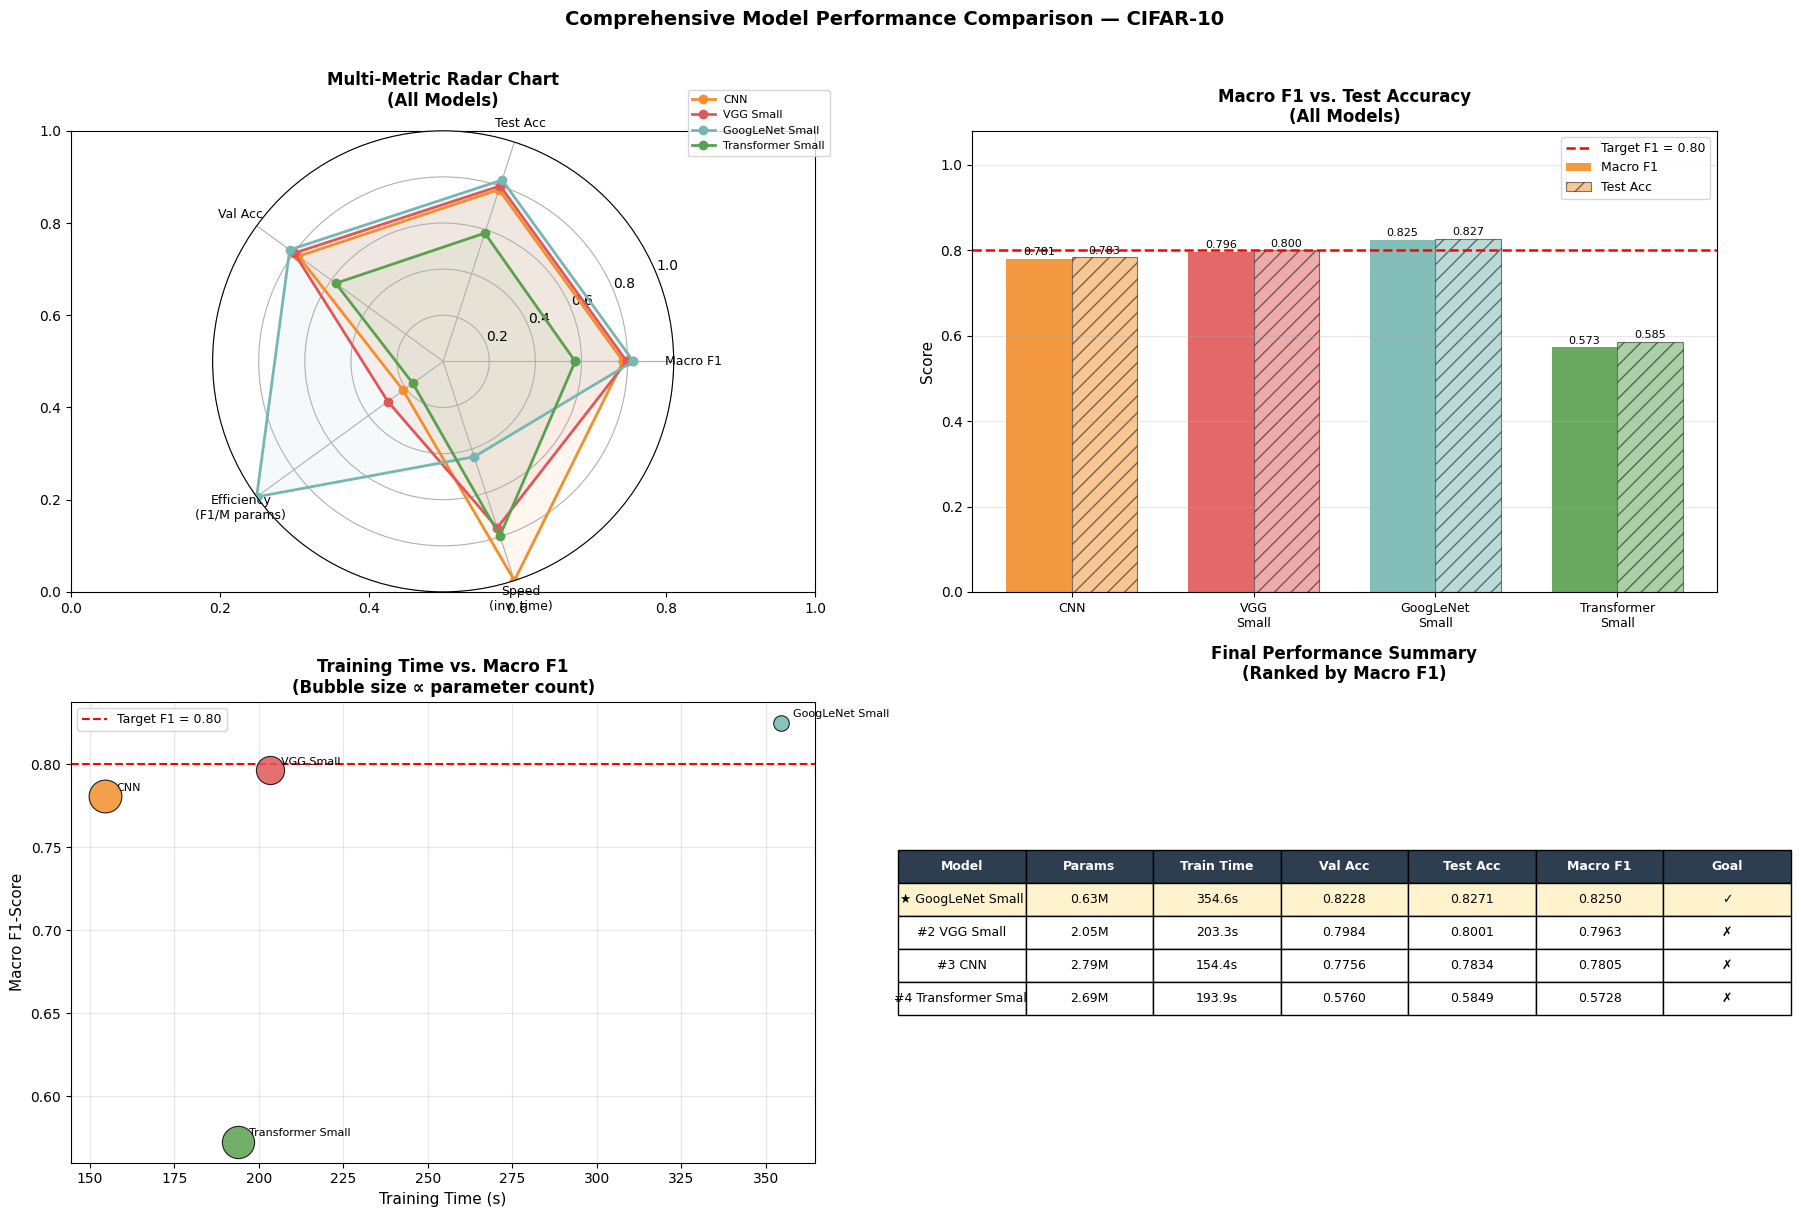

In [31]:
# ── Model Performance Comparison & Interpretation ──
model_order = ['MLP Baseline', 'CNN', 'VGG Small', 'GoogLeNet Small', 'Transformer Small']
available   = [n for n in model_order if n in results]
best_name   = max(results, key=lambda n: results[n]['macro_f1'])

fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# ── 1. Radar / Spider chart (relative performance) ──
metrics = ['Macro F1', 'Test Acc', 'Val Acc', 'Efficiency\n(F1/M params)', 'Speed\n(inv. time)']
n_metrics = len(metrics)
angles = [n / float(n_metrics) * 2 * np.pi for n in range(n_metrics)]
angles += angles[:1]   # close the polygon

ax_radar = plt.subplot(2, 2, 1, polar=True)
ax_radar.set_xticks(angles[:-1])
ax_radar.set_xticklabels(metrics, fontsize=9)
ax_radar.set_ylim(0, 1)

pal = {'MLP Baseline': '#4e79a7', 'CNN': '#f28e2b',
       'VGG Small': '#e15759', 'GoogLeNet Small': '#76b7b2',
       'Transformer Small': '#59a14f'}

max_eff   = max(results[n]['macro_f1'] / (results[n]['num_params'] / 1e6) for n in available)
max_speed = max(1.0 / results[n]['train_time'] for n in available)

for name in available:
    r  = results[name]
    eff   = (r['macro_f1'] / (r['num_params'] / 1e6)) / max_eff
    speed = (1.0 / r['train_time']) / max_speed
    vals  = [r['macro_f1'], r['test_acc'], r['val_acc'], eff, speed]
    vals += vals[:1]
    ax_radar.plot(angles, vals, 'o-', lw=2, label=name, color=pal.get(name, 'grey'))
    ax_radar.fill(angles, vals, alpha=0.07, color=pal.get(name, 'grey'))

ax_radar.set_title('Multi-Metric Radar Chart\n(All Models)', fontsize=12, fontweight='bold', pad=18)
ax_radar.legend(loc='upper right', bbox_to_anchor=(1.35, 1.10), fontsize=8)

# ── 2. Macro F1 + Test Acc grouped bars ──
ax = axes[0][1]
x     = np.arange(len(available))
width = 0.36
b1 = ax.bar(x - width/2, [results[n]['macro_f1']  for n in available], width,
            label='Macro F1',    color=[pal.get(n, 'grey') for n in available], alpha=0.9)
b2 = ax.bar(x + width/2, [results[n]['test_acc']  for n in available], width,
            label='Test Acc',    color=[pal.get(n, 'grey') for n in available], alpha=0.5,
            edgecolor='black', linewidth=0.8, hatch='//')
ax.axhline(0.8, color='red', linestyle='--', lw=1.8, label='Target F1 = 0.80')
ax.set_xticks(x)
ax.set_xticklabels([n.replace(' ', '\n') for n in available], fontsize=9)
ax.set_ylabel('Score', fontsize=11)
ax.set_title('Macro F1 vs. Test Accuracy\n(All Models)', fontsize=12, fontweight='bold')
ax.legend(fontsize=9);  ax.set_ylim(0, 1.08)
ax.grid(axis='y', alpha=0.3)
for b in list(b1) + list(b2):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.004,
            f'{b.get_height():.3f}', ha='center', va='bottom', fontsize=8)

# ── 3. Training time vs Macro F1 ──
ax = axes[1][0]
for name in available:
    r = results[name]
    ax.scatter(r['train_time'], r['macro_f1'],
               s=r['num_params'] / 5000,   # bubble size ∝ params
               color=pal.get(name, 'grey'), alpha=0.85, edgecolors='black', lw=0.8, zorder=5)
    ax.annotate(name, (r['train_time'], r['macro_f1']),
                textcoords='offset points', xytext=(8, 4), fontsize=8)
ax.axhline(0.8, color='red', linestyle='--', lw=1.5, label='Target F1 = 0.80')
ax.set_xlabel('Training Time (s)', fontsize=11)
ax.set_ylabel('Macro F1-Score',    fontsize=11)
ax.set_title('Training Time vs. Macro F1\n(Bubble size ∝ parameter count)',
             fontsize=12, fontweight='bold')
ax.legend(fontsize=9);  ax.grid(alpha=0.3)

# ── 4. Comprehensive ranking table ──
ax = axes[1][1]
ax.axis('off')

col_labels = ['Model', 'Params', 'Train Time', 'Val Acc', 'Test Acc', 'Macro F1', 'Goal']
row_data   = []
ranked_models = sorted(available, key=lambda n: results[n]['macro_f1'], reverse=True)
for rank, name in enumerate(ranked_models, 1):
    r    = results[name]
    goal = 'N/A' if name == 'MLP Baseline' else ('✓' if r['macro_f1'] >= 0.8 else '✗')
    star = '★ ' if name == best_name else f'#{rank} '
    row_data.append([
        f"{star}{name}",
        f"{r['num_params']/1e6:.2f}M",
        f"{r['train_time']:.1f}s",
        f"{r['val_acc']:.4f}",
        f"{r['test_acc']:.4f}",
        f"{r['macro_f1']:.4f}",
        goal
    ])

tbl = ax.table(cellText=row_data, colLabels=col_labels,
               loc='center', cellLoc='center')
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1.2, 1.8)

# Colour header row
for j in range(len(col_labels)):
    tbl[0, j].set_facecolor('#2c3e50')
    tbl[0, j].set_text_props(color='white', fontweight='bold')
# Colour best model row gold
for j in range(len(col_labels)):
    tbl[1, j].set_facecolor('#fff3cd')

ax.set_title('Final Performance Summary\n(Ranked by Macro F1)',
             fontsize=12, fontweight='bold', pad=16)

plt.suptitle('Comprehensive Model Performance Comparison — CIFAR-10',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()